# ASL Citizen -- 1000 classes -- Landmark models: v10 Geometry Transformer + ST-GCN
### Capstone C -- model comparison track (new architecture #2 of 2, plus the 1000-class baseline)

This notebook trains **two** models on the cached MediaPipe landmarks (16 frames x 116 features),
one after the other:

| # | Model | Why |
|---|---|---|
| 1 | **v10 Geometry-Only Transformer** -- the team's model, code + hyperparameters copied unchanged | The 1000-class point of the v10 series, so every architecture in the comparison has a 1000-class number on the identical split |
| 2 | **ST-GCN** (spatial-temporal graph convolutional network) | The standard skeleton-based action/sign-recognition architecture, and the v10 notebook's own suggested future work ("a small temporal-conv or ST-GCN-style module"). Treats the 58 landmarks as a graph (hand bones, arm chain, eyebrows) + a learned adjacency, instead of flattening them into one vector |

Both models read only landmarks, so all landmarks are **pre-loaded into RAM once** (~0.2 GB) --
same numbers, just no repeated disk I/O. Each model trains in well under an hour on one GPU.

---
### How to run on Kaggle
1. *File -> Import Notebook* -> upload this `.ipynb`.
2. **Add Input**: the 3 `asl-shared-cache-building-id0x` notebook outputs + the `asl-citizen` dataset
   (paths auto-discovered).
3. Accelerator = **GPU T4 x1 or P100** (one GPU is plenty). Internet not required.
4. *(Optional)* `SMOKE_TEST = True` -> Run All (~3-5 min) -> back to `False`.
5. **Save Version -> Save & Run All (Commit)**. Estimated **1-2 h total** (dominated by
   preloading ~31k `.npz` files and the batch-size-8 v10 schedule).
6. Download `landmark_models_1000cls/` from the Output tab.

Run this **at the same time** as `train_1000_swin3d_t.ipynb` -- they don't depend on each other.

## 1. Setup

In [1]:
import csv
import glob
import hashlib
import json
import math
import os
import random
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

NOTEBOOK_START = time.time()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_GPUS = torch.cuda.device_count()


def _env(name, default):
    # Environment overrides exist ONLY for the local CPU smoke test of this notebook.
    # On Kaggle none of these are set, so the defaults in CONFIG below are what run.
    return os.environ.get(name, default)


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


print(f"Torch {torch.__version__} | device={DEVICE} | GPUs={N_GPUS}")
for i in range(N_GPUS):
    print(f"  cuda:{i} -> {torch.cuda.get_device_name(i)}")

Torch 2.10.0+cu128 | device=cuda | GPUs=2
  cuda:0 -> Tesla T4
  cuda:1 -> Tesla T4


## 2. Configuration

In [2]:
class CONFIG:
    WORK_DIR = Path(_env("ASL_WORK_DIR", "/kaggle/working"))

    CACHE_DIRS = [
        Path("/kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0"),
        Path("/kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2"),
        Path("/kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1"),
    ]
    SPLITS_DIR = Path("/kaggle/input/datasets/pranaysahaps/asl-citizen/splits")
    OUT_DIR = WORK_DIR / "landmark_models_1000cls"

    TOP_K_CLASSES = int(_env("ASL_TOP_K", 1000))

    # ---- cache layout (v10 CONFIG, unchanged) ----
    FRAME_COUNT = 16
    N_HAND_LANDMARKS = 21
    POSE_SUBSET_IDX = [11, 12, 13, 14, 15, 16]
    FACE_SUBSET_IDX = [70, 63, 105, 66, 107, 336, 296, 334, 293, 300]

    # ---- which models to train (in order) ----
    MODELS_TO_RUN = ["geometry_transformer_v10", "stgcn"]

    SMOKE_TEST = _env("ASL_SMOKE_TEST", "0") == "1"
    SMOKE_SAMPLES = {"train": 512, "val": 256, "test": 256}
    PRELOAD_THREADS = 16
    SEED = 42


N_POINTS = CONFIG.N_HAND_LANDMARKS * 2 + len(CONFIG.POSE_SUBSET_IDX) + len(CONFIG.FACE_SUBSET_IDX)  # 58
LANDMARK_VECTOR_DIM = N_POINTS * 2                                                                 # 116
print(f"Landmark points per frame: {N_POINTS} -> vector dim {LANDMARK_VECTOR_DIM}")


def resolve_inputs():
    """Use CONFIG paths if they exist; otherwise auto-discover the cache shards / splits
    under /kaggle/input (Kaggle mount paths change depending on how inputs are attached)."""
    env_cache = os.environ.get("ASL_CACHE_DIRS")
    if env_cache:
        CONFIG.CACHE_DIRS = [Path(p) for p in env_cache.split(os.pathsep)]
    env_splits = os.environ.get("ASL_SPLITS_DIR")
    if env_splits:
        CONFIG.SPLITS_DIR = Path(env_splits)

    if not all(p.exists() for p in CONFIG.CACHE_DIRS):
        found = sorted({Path(p) for p in glob.glob("/kaggle/input/**/feature_cache_shard_*", recursive=True)
                        if Path(p).is_dir()})
        print(f"[inputs] configured CACHE_DIRS not all present -- auto-discovered {len(found)} shard dirs:")
        for p in found:
            print("   ", p)
        CONFIG.CACHE_DIRS = found
    assert CONFIG.CACHE_DIRS, ("No feature_cache_shard_* directories found. Attach the three "
                               "asl-shared-cache-building notebooks' outputs as inputs (see top of notebook).")
    if len(CONFIG.CACHE_DIRS) != 3:
        print(f"[inputs] WARNING: expected 3 cache shards (as in the v10 notebooks), found "
              f"{len(CONFIG.CACHE_DIRS)}. The class subset may differ from the v10 runs.")

    if not (CONFIG.SPLITS_DIR / "train.csv").exists():
        hits = sorted(glob.glob("/kaggle/input/**/splits/train.csv", recursive=True))
        assert hits, "ASL Citizen splits/train.csv not found -- attach the asl-citizen dataset."
        CONFIG.SPLITS_DIR = Path(hits[0]).parent
        print(f"[inputs] auto-discovered SPLITS_DIR: {CONFIG.SPLITS_DIR}")
    print("Cache shards:", *CONFIG.CACHE_DIRS, sep="\n   ")
    print("Splits dir:  ", CONFIG.SPLITS_DIR)


resolve_inputs()
seed_everything(CONFIG.SEED)
CONFIG.OUT_DIR.mkdir(parents=True, exist_ok=True)

Landmark points per frame: 58 -> vector dim 116
Cache shards:
   /kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0
   /kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2
   /kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1
Splits dir:   /kaggle/input/datasets/pranaysahaps/asl-citizen/splits


## Build the manifest & apply the Top-1000 class filter

**Copied verbatim** from the team's v10 notebook (Section 3): rebuild the label space from the
official ASL Citizen `train.csv` / `val.csv` / `test.csv`, restricted to videos present in the
cache, then keep the `TOP_K_CLASSES` most-represented classes (remapped to `0..K-1`, most
represented = index 0). Same code + same cache = same 1000 classes and same index mapping as the
team's other 1000-class runs, so every model in the comparison is evaluated on the identical
signer-independent test split.

The class list is saved to `class_list.json` with a fingerprint -- both notebooks print it, and
**the fingerprints must match** for the comparison to be valid.

In [3]:
cache_index = {}
for shard_dir in CONFIG.CACHE_DIRS:
    assert shard_dir.exists(), f"Cache shard not found: {shard_dir} -- update CONFIG.CACHE_DIRS"
    for f in shard_dir.glob("*.npz"):
        cache_index[f.stem] = f
print(f"Total cached .npz files across {len(CONFIG.CACHE_DIRS)} shards: {len(cache_index)}")

split_files = {
    "train": CONFIG.SPLITS_DIR / "train.csv",
    "val": CONFIG.SPLITS_DIR / "val.csv",
    "test": CONFIG.SPLITS_DIR / "test.csv",
}
rows, all_glosses = [], set()
for subset, csv_path in split_files.items():
    assert csv_path.exists(), f"Missing split file: {csv_path}"
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            gloss = row["Gloss"]
            all_glosses.add(gloss)
            if video_id in cache_index:
                rows.append((video_id, gloss, subset))

class_list_full = sorted(all_glosses)
class_to_idx_full = {g: i for i, g in enumerate(class_list_full)}

nslt_data_full = {}
for video_id, gloss, subset in rows:
    nslt_data_full[video_id] = {"action": [class_to_idx_full[gloss], 0, 0], "subset": subset}

print(f"Cached rows matched against splits: {len(rows)}")
print(f"Full ASL Citizen vocabulary present in cache: {len(class_list_full)} classes")

# --- top-K filter, identical remap logic to the v10 notebooks ---
class_video_counts = Counter(v["action"][0] for v in nslt_data_full.values())
top_k_old_indices = [c for c, _ in class_video_counts.most_common(CONFIG.TOP_K_CLASSES)]
top_k_old_indices_set = set(top_k_old_indices)
old_to_new_idx = {old_idx: new_idx for new_idx, old_idx in enumerate(top_k_old_indices)}

nslt_data = {
    vid: {"action": [old_to_new_idx[meta["action"][0]], 0, 0], "subset": meta["subset"]}
    for vid, meta in nslt_data_full.items()
    if meta["action"][0] in top_k_old_indices_set
}
class_list = {old_to_new_idx[old]: class_list_full[old] for old in top_k_old_indices}
NUM_CLASSES = len(class_list)

subset_counts = Counter(v["subset"] for v in nslt_data.values())
print(f"\nTop-{CONFIG.TOP_K_CLASSES} filter applied -- NUM_CLASSES: {NUM_CLASSES}")
print(f"Videos remaining: {len(nslt_data)} across splits {dict(subset_counts)}")

per_class_counts = Counter(v["action"][0] for v in nslt_data.values())
print(f"Videos/class (post-filter, all splits combined): "
      f"min={min(per_class_counts.values())} median={int(np.median(list(per_class_counts.values())))} "
      f"max={max(per_class_counts.values())}")

# --- added: persist the exact class mapping for the web app + cross-notebook check ---
CLASS_NAMES = [class_list[i] for i in range(NUM_CLASSES)]
CLASS_FINGERPRINT = hashlib.sha1("\n".join(CLASS_NAMES).encode("utf-8")).hexdigest()[:12]
with open(CONFIG.OUT_DIR / "class_list.json", "w", encoding="utf-8") as f:
    json.dump({"num_classes": NUM_CLASSES, "fingerprint": CLASS_FINGERPRINT,
               "rule": f"ASL Citizen top-{CONFIG.TOP_K_CLASSES} most-represented glosses in cache "
                       f"(Counter.most_common), index 0 = most represented",
               "classes": CLASS_NAMES}, f, indent=1)
print(f"\nClass-list fingerprint: {CLASS_FINGERPRINT}   (must match across all 1000-class notebooks)")


def split_samples(subset):
    # Same sample construction (and order) as the v10 WLASLCachedDataset.
    s = [(vid, meta["action"][0]) for vid, meta in nslt_data.items()
         if meta["subset"] == subset and vid in cache_index]
    if CONFIG.SMOKE_TEST:
        rng = random.Random(0)
        s = rng.sample(s, min(len(s), CONFIG.SMOKE_SAMPLES[subset]))
    return s


train_samples, val_samples, test_samples = (split_samples(s) for s in ("train", "val", "test"))
print(f"Train / val / test samples: {len(train_samples)} / {len(val_samples)} / {len(test_samples)}"
      + ("   [SMOKE TEST SUBSET]" if CONFIG.SMOKE_TEST else ""))

Total cached .npz files across 3 shards: 63550
Cached rows matched against splits: 63550
Full ASL Citizen vocabulary present in cache: 2731 classes

Top-1000 filter applied -- NUM_CLASSES: 1000
Videos remaining: 30909 across splits {'train': 14571, 'val': 3778, 'test': 12560}
Videos/class (post-filter, all splits combined): min=30 median=31 max=32

Class-list fingerprint: 72d3ef78291c   (must match across all 1000-class notebooks)
Train / val / test samples: 14571 / 3778 / 12560


## 3. Pre-load landmarks into memory
Exactly the tensor v10's `WLASLCachedDataset` returned: `data["landmarks"]` as float32 with
`nan_to_num(nan=0, posinf=0, neginf=0)`. Only the `landmarks` member of each `.npz` is read.

In [4]:
def load_landmarks(vid):
    with np.load(cache_index[vid]) as d:
        x = np.asarray(d["landmarks"], dtype=np.float32)
    return np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)


def preload(samples, name):
    t0 = time.time()
    with ThreadPoolExecutor(CONFIG.PRELOAD_THREADS) as ex:
        arr = list(ex.map(load_landmarks, [v for v, _ in samples]))
    X = torch.from_numpy(np.stack(arr))
    y = torch.tensor([c for _, c in samples], dtype=torch.long)
    print(f"{name}: {tuple(X.shape)} loaded in {time.time() - t0:.0f}s")
    return X, y


X_train, y_train = preload(train_samples, "train")
X_val, y_val = preload(val_samples, "val")
X_test, y_test = preload(test_samples, "test")
assert X_train.shape[1:] == (CONFIG.FRAME_COUNT, LANDMARK_VECTOR_DIM), X_train.shape
print(f"value range: [{X_train.min():.3f}, {X_train.max():.3f}] | "
      f"all-zero frames: {(X_train.abs().sum(-1) == 0).float().mean():.1%}")

train: (14571, 16, 116) loaded in 51s
val: (3778, 16, 116) loaded in 13s
test: (12560, 16, 116) loaded in 44s
value range: [-2.601, 2.842] | all-zero frames: 0.0%


## 4. Verify the landmark layout (needed only for the ST-GCN graph)
The v10 Transformer consumes the flat 116-vector, so it doesn't care how points are packed. ST-GCN
needs to know which numbers form each `(x, y)` point. Rather than assume, this cell **tests both
plausible packings** against hand anatomy: in the correct one, MediaPipe's 21 hand-bone pairs are much
shorter than the average distance between arbitrary hand points.

In [5]:
HAND_EDGES = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8), (5, 9), (9, 10), (10, 11),
              (11, 12), (9, 13), (13, 14), (14, 15), (15, 16), (13, 17), (17, 18), (18, 19), (19, 20), (0, 17)]


def to_points(X, packing):
    # X: (..., 116) -> (..., 58, 2)
    if packing == "interleaved":            # [x0, y0, x1, y1, ...]
        return X.reshape(*X.shape[:-1], N_POINTS, 2)
    if packing == "planar":                 # [x0..x57, y0..y57]
        return X.reshape(*X.shape[:-1], 2, N_POINTS).transpose(-1, -2)
    raise ValueError(packing)


def hand_bone_ratio(X, packing, hand_offset):
    P = to_points(X.reshape(-1, LANDMARK_VECTOR_DIM), packing)[:, hand_offset:hand_offset + 21]
    P = P[P.abs().sum(dim=(1, 2)) > 0]                       # frames where this hand was detected
    if len(P) < 50:
        return float("nan")
    D = torch.cdist(P, P)                                    # (M, 21, 21)
    bone = torch.stack([D[:, i, j] for i, j in HAND_EDGES], 1).mean()
    iu = torch.triu_indices(21, 21, 1)
    return float(bone / D[:, iu[0], iu[1]].mean())


sample_X = X_train[:min(len(X_train), 4000)]
ratios = {pk: [hand_bone_ratio(sample_X, pk, off) for off in (0, 21)] for pk in ("interleaved", "planar")}
for pk, r in ratios.items():
    print(f"{pk:12s} bone/avg-distance ratio -- hand block 0: {r[0]:.3f} | hand block 1: {r[1]:.3f}")
score = {pk: np.nanmean(r) for pk, r in ratios.items()}
LANDMARK_PACKING = min(score, key=score.get)
other = max(score, key=score.get)
LAYOUT_CONFIDENT = bool(score[LANDMARK_PACKING] < 0.7 * score[other])
print(f"\n-> using packing '{LANDMARK_PACKING}' "
      f"({'clear anatomical match' if LAYOUT_CONFIDENT else 'NOT conclusive -- ST-GCN will lean on its learned adjacency'})")

interleaved  bone/avg-distance ratio -- hand block 0: 0.511 | hand block 1: 0.500
planar       bone/avg-distance ratio -- hand block 0: 1.469 | hand block 1: 0.826

-> using packing 'interleaved' (clear anatomical match)


## 5. Models

**Model 1 -- v10 Geometry-Only Transformer:** `GeometryStream`, `PositionalEncoding`,
`GeometryOnlySLRModel` copied unchanged from the v10 notebook (D_MODEL 256, 4 heads, 3 layers,
FFN 512, dropout 0.5; input = coords + frame-to-frame velocity).

**Model 2 -- ST-GCN (adaptive graph):** input per frame = 58 nodes x (x, y, vx, vy). Graph =
self-loops + MediaPipe hand bones (both hands) + shoulder-elbow-wrist chains + eyebrow chains,
symmetrically normalised, **plus a learnable adjacency** per layer (2s-AGCN style) so the network can
learn hand-to-wrist, hand-to-face and two-hand relations the fixed skeleton does not encode.
7 blocks (64-64-64-128-128-256-256 channels, temporal kernel 5, temporal stride 2 at 128 and 256),
global average pooling, dropout 0.5, linear head.

In [6]:
# ---------------- Model 1: v10, unchanged ----------------
class V10:
    LANDMARK_EMBED_DIM = 128
    D_MODEL = 256
    N_HEADS = 4
    N_ENCODER_LAYERS = 3
    FFN_DIM = 512
    DROPOUT = 0.5


class GeometryStream(nn.Module):
    def __init__(self, input_dim=LANDMARK_VECTOR_DIM, embed_dim=V10.LANDMARK_EMBED_DIM):
        super().__init__()
        self.project = nn.Sequential(nn.Linear(input_dim * 2, embed_dim), nn.ReLU(), nn.LayerNorm(embed_dim))

    def forward(self, x):
        velocity = torch.zeros_like(x)
        velocity[:, 1:] = x[:, 1:] - x[:, :-1]
        return self.project(torch.cat([x, velocity], dim=-1))


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=CONFIG.FRAME_COUNT):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class GeometryOnlySLRModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.geometry_stream = GeometryStream()
        self.to_d_model = nn.Linear(V10.LANDMARK_EMBED_DIM, V10.D_MODEL)
        self.pos_encoding = PositionalEncoding(V10.D_MODEL)
        encoder_layer = nn.TransformerEncoderLayer(d_model=V10.D_MODEL, nhead=V10.N_HEADS,
                                                   dim_feedforward=V10.FFN_DIM, dropout=V10.DROPOUT,
                                                   batch_first=True)
        self.temporal_encoder = nn.TransformerEncoder(encoder_layer, num_layers=V10.N_ENCODER_LAYERS)
        self.word_head = nn.Linear(V10.D_MODEL, num_classes)

    def forward(self, landmarks):
        fused = self.pos_encoding(self.to_d_model(self.geometry_stream(landmarks)))
        return self.word_head(self.temporal_encoder(fused).mean(dim=1))


# ---------------- Model 2: ST-GCN ----------------
def skeleton_edges():
    e = []
    for off in (0, 21):                                         # two hands
        e += [(i + off, j + off) for i, j in HAND_EDGES]
    p = {idx: 42 + k for k, idx in enumerate(CONFIG.POSE_SUBSET_IDX)}   # pose 11..16 -> nodes 42..47
    e += [(p[11], p[12]), (p[11], p[13]), (p[13], p[15]), (p[12], p[14]), (p[14], p[16])]
    f0 = 42 + len(CONFIG.POSE_SUBSET_IDX)                        # eyebrows -> nodes 48..57
    e += [(f0 + i, f0 + i + 1) for i in range(4)] + [(f0 + 5 + i, f0 + 6 + i) for i in range(4)]
    return e


def normalized_adjacency(V, edges):
    A = torch.eye(V)
    for i, j in edges:
        A[i, j] = A[j, i] = 1.0
    d = A.sum(1).pow(-0.5)
    return d[:, None] * A * d[None, :]


class AdaptiveGraphConv(nn.Module):
    def __init__(self, cin, cout, A):
        super().__init__()
        self.register_buffer("A", A)
        self.B = nn.Parameter(torch.zeros_like(A))              # learned adjacency, starts at 0
        self.conv = nn.Conv2d(cin, cout, 1)

    def forward(self, x):                                       # x: (N, C, T, V)
        return torch.einsum("nctv,vw->nctw", self.conv(x), self.A + self.B)


class STGCNBlock(nn.Module):
    def __init__(self, cin, cout, A, stride=1, dropout=0.1, kt=5):
        super().__init__()
        self.gcn = AdaptiveGraphConv(cin, cout, A)
        self.bn1 = nn.BatchNorm2d(cout)
        self.tcn = nn.Sequential(nn.Conv2d(cout, cout, (kt, 1), (stride, 1), ((kt - 1) // 2, 0)),
                                 nn.BatchNorm2d(cout), nn.Dropout(dropout))
        if cin == cout and stride == 1:
            self.res = nn.Identity()
        else:
            self.res = nn.Sequential(nn.Conv2d(cin, cout, 1, (stride, 1)), nn.BatchNorm2d(cout))

    def forward(self, x):
        return F.relu(self.tcn(F.relu(self.bn1(self.gcn(x)))) + self.res(x))


class STGCN(nn.Module):
    def __init__(self, num_classes, packing, in_ch=4, dropout=0.5):
        super().__init__()
        self.packing = packing
        A = normalized_adjacency(N_POINTS, skeleton_edges())
        self.data_bn = nn.BatchNorm1d(in_ch * N_POINTS)
        cfg = [(in_ch, 64, 1), (64, 64, 1), (64, 64, 1), (64, 128, 2), (128, 128, 1), (128, 256, 2), (256, 256, 1)]
        self.blocks = nn.ModuleList(STGCNBlock(i, o, A, s) for i, o, s in cfg)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, landmarks):                               # (N, T, 116) -- same input as v10
        N, T, _ = landmarks.shape
        pts = to_points(landmarks, self.packing)                # (N, T, V, 2)
        vel = torch.zeros_like(pts)
        vel[:, 1:] = pts[:, 1:] - pts[:, :-1]
        x = torch.cat([pts, vel], -1)                           # (N, T, V, 4)
        x = x.permute(0, 2, 3, 1).reshape(N, N_POINTS * 4, T)   # (N, V*C, T)
        x = self.data_bn(x).reshape(N, N_POINTS, 4, T).permute(0, 2, 3, 1)   # (N, C, T, V)
        for blk in self.blocks:
            x = blk(x)
        return self.fc(self.drop(x.mean(dim=(2, 3))))


def augment_landmarks(x):
    """ST-GCN only: per-clip random scale/rotate/shift of *detected* points (zeros = missing stay zero)."""
    N = x.shape[0]
    pts = to_points(x, LANDMARK_PACKING).clone()                # (N, T, V, 2)
    mask = (pts.abs().sum(-1, keepdim=True) > 0).float()
    centre = 0.5
    s = torch.empty(N, 1, 1, 1, device=x.device).uniform_(0.9, 1.1)
    th = torch.empty(N, device=x.device).uniform_(-math.radians(10), math.radians(10))
    R = torch.stack([torch.stack([th.cos(), -th.sin()], -1), torch.stack([th.sin(), th.cos()], -1)], -2)
    shift = torch.empty(N, 1, 1, 2, device=x.device).uniform_(-0.05, 0.05)
    p = (pts - centre) * s
    p = torch.einsum("ntvc,ndc->ntvd", p, R) + centre + shift
    pts = p * mask
    if LANDMARK_PACKING == "interleaved":
        return pts.reshape(N, x.shape[1], -1)
    return pts.transpose(-1, -2).reshape(N, x.shape[1], -1)


# ---------------- per-model training recipes ----------------
MODEL_SPECS = {
    "geometry_transformer_v10": dict(   # v10 CONFIG values, unchanged
        display_name="Geometry Transformer (v10, landmarks)",
        build=lambda: GeometryOnlySLRModel(NUM_CLASSES),
        batch_size=8, lr=1e-4, weight_decay=3e-4, grad_clip=0.5, label_smoothing=0.1,
        epochs=50, warmup_epochs=0, scheduler="cosine_epoch",
        min_epochs=30, patience=8, augment=False),
    "stgcn": dict(
        display_name="ST-GCN (landmarks)",
        build=lambda: STGCN(NUM_CLASSES, LANDMARK_PACKING),
        batch_size=32, lr=1e-3, weight_decay=5e-4, grad_clip=1.0, label_smoothing=0.1,
        epochs=80, warmup_epochs=3, scheduler="warmup_cosine_step",
        min_epochs=30, patience=12, augment=True),
}
for name in CONFIG.MODELS_TO_RUN:
    m = MODEL_SPECS[name]["build"]()
    out = m(X_train[:2])
    print(f"{name:26s} params={sum(p.numel() for p in m.parameters()):>10,}  output={tuple(out.shape)}")

geometry_transformer_v10   params= 1,901,416  output=(2, 1000)
stgcn                      params= 1,341,300  output=(2, 1000)


## 6. Train + evaluate each model
Same protocol as v10 for both: `WeightedRandomSampler`, label smoothing, gradient clipping,
NaN guard, best checkpoint on **val top-1**, early stopping with a minimum-epoch floor, then a single
pass over the held-out test split with the best checkpoint. fp32 throughout (as in v10).


========== geometry_transformer_v10: 1,901,416 params, up to 50 epochs ==========
epoch   1 | train 6.705/0.004 | val 6.374/0.010/0.041  *best* | 0.3 min
epoch   2 | train 6.174/0.019 | val 5.912/0.028/0.100  *best* | 0.6 min
epoch   3 | train 5.742/0.047 | val 5.431/0.062/0.193  *best* | 0.9 min
epoch   4 | train 5.294/0.095 | val 5.044/0.093/0.281  *best* | 1.2 min
epoch   5 | train 4.901/0.144 | val 4.720/0.129/0.362  *best* | 1.5 min
epoch   6 | train 4.581/0.200 | val 4.345/0.214/0.475  *best* | 1.8 min
epoch   7 | train 4.252/0.264 | val 4.167/0.226/0.522  *best* | 2.1 min
epoch   8 | train 4.002/0.315 | val 3.922/0.292/0.594  *best* | 2.4 min
epoch   9 | train 3.726/0.385 | val 3.720/0.345/0.651  *best* | 2.7 min
epoch  10 | train 3.510/0.427 | val 3.576/0.356/0.681  *best* | 3.0 min
epoch  11 | train 3.305/0.479 | val 3.374/0.415/0.725  *best* | 3.3 min
epoch  12 | train 3.098/0.535 | val 3.252/0.445/0.754  *best* | 3.6 min
epoch  13 | train 2.967/0.562 | val 3.172/0.476/0.765

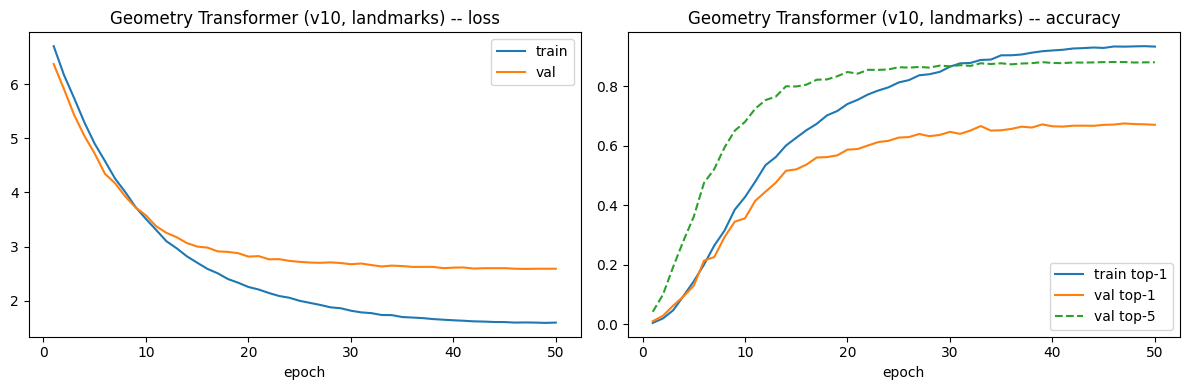

[geometry_transformer_v10] top confused pairs:
      true           pred  errors
      LATE         NOTYET       8
 MEGAPHONE        BALLOON       7
  THANKYOU           GOOD       7
    DEGREE           TUBE       7
       TWO FRIENDSNOMORE1       7
HEARTTOUCH      HEARTBODY       7
  EXERCISE        WORKOUT       7
      STAR          STARS       7
     BRAVE         HEALTH       6
 WEWILLSEE         SEESEE       6

geometry_transformer_v10 TEST: top-1 0.575 | top-5 0.818 | macro-F1 0.571 | best epoch 47 | 15.0 min | CPU latency 3.2 ms

========== stgcn: 1,341,300 params, up to 80 epochs ==========
epoch   1 | train 6.982/0.002 | val 6.819/0.003/0.011  *best* | 0.4 min
epoch   2 | train 6.723/0.003 | val 6.544/0.005/0.020  *best* | 0.9 min
epoch   4 | train 6.150/0.012 | val 5.865/0.020/0.083  *best* | 1.7 min
epoch   5 | train 5.841/0.021 | val 5.584/0.034/0.126  *best* | 2.1 min
epoch   6 | train 5.572/0.036 | val 5.315/0.048/0.183  *best* | 2.5 min
epoch   7 | train 5.299/0.062 | 

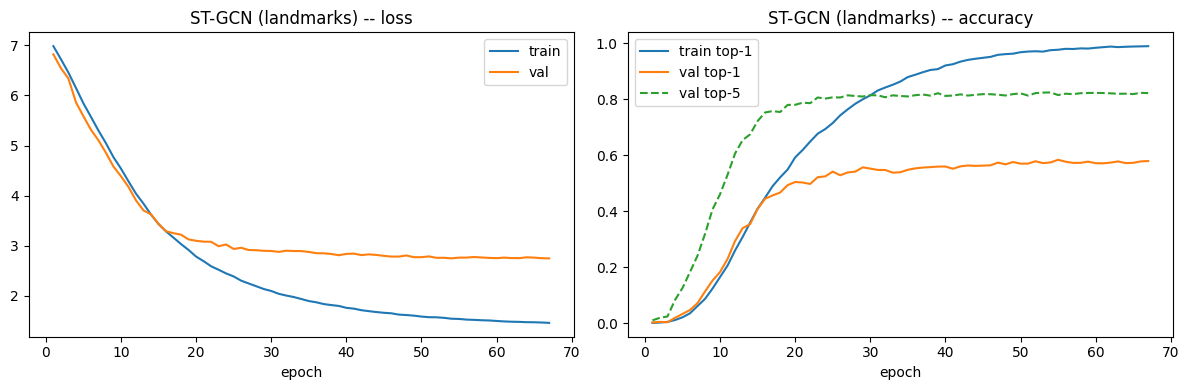

[stgcn] top confused pairs:
        true        pred  errors
     SUSPECT        MIND       9
       PIANO    BEHAVIOR       7
CONFIDENTIAL      SECRET       7
       CLEAR     OBVIOUS       7
        KNOW THINKPONDER       6
       BRAVE      HEALTH       6
      BRIGHT     OBVIOUS       6
      HUNGRY        WISH       6
       STARS        STAR       6
   HEARTBODY  HEARTTOUCH       6

stgcn TEST: top-1 0.488 | top-5 0.740 | macro-F1 0.484 | best epoch 55 | 27.7 min | CPU latency 10.1 ms


In [7]:
def summarize_predictions(y_true, y_pred, top5, num_classes):
    labels = list(range(num_classes))
    mp, mr, mf, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    wp, wr, wf, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="weighted", zero_division=0)
    return {
        "top1": float((y_true == y_pred).mean()),
        "top5": float(np.mean([t in row for t, row in zip(y_true, top5)])),
        "macro_precision": float(mp), "macro_recall": float(mr), "macro_f1": float(mf),
        "weighted_precision": float(wp), "weighted_recall": float(wr), "weighted_f1": float(wf),
        "n_samples": int(len(y_true)),
    }


def save_evaluation(out_dir, tag, preds, video_ids, class_names):
    """Writes metrics-ready artifacts the web app reads directly."""
    out_dir.mkdir(parents=True, exist_ok=True)
    y_true, y_pred = preds["y_true"], preds["y_pred"]
    n = len(class_names)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n)))
    np.savez_compressed(out_dir / "confusion_matrix.npz", cm=cm.astype(np.uint16))

    p, r, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=list(range(n)), zero_division=0)
    pd.DataFrame({"class_id": range(n), "class_name": class_names, "support": sup,
                  "correct": np.diag(cm), "precision": p, "recall": r, "f1": f1}
                 ).to_csv(out_dir / "per_class_metrics.csv", index=False)

    pd.DataFrame({"video_id": video_ids, "y_true": y_true, "y_pred": y_pred,
                  "confidence": preds["confidence"],
                  "top5": [" ".join(map(str, t)) for t in preds["top5"]]}
                 ).to_csv(out_dir / "test_predictions.csv", index=False)

    pairs = [(class_names[t], class_names[q], int(cm[t, q])) for t, q in zip(*np.nonzero(cm)) if t != q]
    pairs_df = pd.DataFrame(pairs, columns=["true", "pred", "errors"]).sort_values("errors", ascending=False)
    pairs_df.head(50).to_csv(out_dir / "top_confusion_pairs.csv", index=False)
    print(f"[{tag}] top confused pairs:")
    print(pairs_df.head(10).to_string(index=False))
    return cm


def plot_history(history, title, path):
    if not history:
        return
    ep = [h["epoch"] for h in history]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, [h["train_loss"] for h in history], label="train")
    ax[0].plot(ep, [h["val_loss"] for h in history], label="val")
    ax[0].set_title(f"{title} -- loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, [h["train_top1"] for h in history], label="train top-1")
    ax[1].plot(ep, [h["val_top1"] for h in history], label="val top-1")
    ax[1].plot(ep, [h["val_top5"] for h in history], label="val top-5", linestyle="--")
    ax[1].set_title(f"{title} -- accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(path, dpi=120, bbox_inches="tight"); plt.show()


def measure_cpu_latency(model_cpu, example, n_runs=3, threads=2):
    """Single-clip CPU latency, roughly what a free 2-vCPU host sees (indicative only)."""
    prev = torch.get_num_threads()
    torch.set_num_threads(threads)
    model_cpu.eval()
    with torch.inference_mode():
        model_cpu(example)  # warm-up
        times = []
        for _ in range(n_runs):
            t0 = time.perf_counter(); model_cpu(example); times.append(time.perf_counter() - t0)
    torch.set_num_threads(prev)
    return {"cpu_threads": threads, "mean_s": float(np.mean(times)), "runs": n_runs}


def batches(X, y, bs, sampler=None):
    idx = list(sampler) if sampler is not None else list(range(len(X)))
    for i in range(0, len(idx) - (bs - 1 if sampler is not None else 0), bs):
        j = torch.tensor(idx[i:i + bs])
        if len(j) == 0:
            break
        yield X[j], y[j]


def topk_correct(logits, y, k):
    k = min(k, logits.shape[1])
    return logits.topk(k, dim=1).indices.eq(y.unsqueeze(1)).any(dim=1).sum().item()


@torch.inference_mode()
def predict(model, X, bs=256):
    model.eval()
    probs = []
    for i in range(0, len(X), bs):
        probs.append(torch.softmax(model(X[i:i + bs].to(DEVICE)), 1).cpu())
    return torch.cat(probs)


def train_and_evaluate(name):
    spec = MODEL_SPECS[name]
    out_dir = CONFIG.OUT_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)
    seed_everything(CONFIG.SEED)
    model = spec["build"]().to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    epochs = 1 if CONFIG.SMOKE_TEST else spec["epochs"]
    min_epochs = 1 if CONFIG.SMOKE_TEST else spec["min_epochs"]

    criterion = nn.CrossEntropyLoss(label_smoothing=spec["label_smoothing"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=spec["lr"], weight_decay=spec["weight_decay"])
    counts = Counter(y_train.tolist())
    weights = [1.0 / counts[c] for c in y_train.tolist()]
    steps_per_epoch = len(X_train) // spec["batch_size"]
    if spec["scheduler"] == "cosine_epoch":                 # v10: CosineAnnealingLR(T_max=EPOCHS), per epoch
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
        step_sched = False
    else:
        total, warm = epochs * steps_per_epoch, spec["warmup_epochs"] * steps_per_epoch
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: (s + 1) / max(1, warm) if s < warm
                                                      else 0.5 * (1 + math.cos(math.pi * min(1.0, (s - warm) / max(1, total - warm)))))
        step_sched = True

    history, best_val, best_epoch, ewi = [], -1.0, 0, 0
    best_path = out_dir / "best_model.pt"
    t_start = time.time()
    print(f"\n========== {name}: {n_params:,} params, up to {epochs} epochs ==========")
    for epoch in range(1, epochs + 1):
        model.train()
        sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
        tl, c1, c5, n = 0.0, 0, 0, 0
        for xb, yb in batches(X_train, y_train, spec["batch_size"], sampler):
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            if spec["augment"]:
                xb = augment_landmarks(xb)
            logits = model(xb)
            loss = criterion(logits, yb)
            if not torch.isfinite(loss):
                continue
            optimizer.zero_grad()
            loss.backward()
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), spec["grad_clip"])
            if not torch.isfinite(gn):
                continue
            optimizer.step()
            if step_sched:
                scheduler.step()
            tl += loss.item() * len(yb); c1 += topk_correct(logits, yb, 1); c5 += topk_correct(logits, yb, 5); n += len(yb)
        if not step_sched:
            scheduler.step()

        model.eval()
        vl, v1, v5, vn = 0.0, 0, 0, 0
        with torch.no_grad():
            for xb, yb in batches(X_val, y_val, 256):
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                vl += criterion(logits, yb).item() * len(yb); v1 += topk_correct(logits, yb, 1)
                v5 += topk_correct(logits, yb, 5); vn += len(yb)
        if any(not torch.isfinite(p).all() for p in model.parameters()):
            print(f"[STOPPING] NaN weights at epoch {epoch}; best checkpoint intact."); break

        rec = {"epoch": epoch, "train_loss": tl / max(n, 1), "train_top1": c1 / max(n, 1), "train_top5": c5 / max(n, 1),
               "val_loss": vl / vn, "val_top1": v1 / vn, "val_top5": v5 / vn}
        history.append(rec)
        is_best = rec["val_top1"] > best_val
        if is_best:
            best_val, best_epoch, ewi = rec["val_top1"], epoch, 0
            torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_top1": best_val,
                        "val_loss": rec["val_loss"]}, best_path)
        else:
            ewi += 1
        if epoch == 1 or epoch % 5 == 0 or is_best:
            print(f"epoch {epoch:3d} | train {rec['train_loss']:.3f}/{rec['train_top1']:.3f} | "
                  f"val {rec['val_loss']:.3f}/{rec['val_top1']:.3f}/{rec['val_top5']:.3f}"
                  f"{'  *best*' if is_best else ''} | {(time.time() - t_start) / 60:.1f} min")
        if not is_best and epoch >= min_epochs and ewi >= spec["patience"]:
            print(f"early stopping at epoch {epoch} (no val_top1 gain for {spec['patience']} epochs)"); break

    train_minutes = (time.time() - t_start) / 60
    with open(out_dir / "training_history.json", "w") as f:
        json.dump(history, f, indent=1)
    best = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(best["model_state_dict"])
    plot_history(history, spec["display_name"], out_dir / "training_curves.png")

    # ---- test: touched once ----
    t0 = time.time()
    probs = predict(model, X_test)
    gpu_test_s = time.time() - t0
    preds = {"y_true": y_test.numpy(), "y_pred": probs.argmax(1).numpy(), "confidence": probs.max(1).values.numpy(),
             "top5": probs.topk(min(5, NUM_CLASSES), 1).indices.numpy()}
    test_metrics = summarize_predictions(preds["y_true"], preds["y_pred"], preds["top5"], NUM_CLASSES)
    save_evaluation(out_dir, name, preds, [v for v, _ in test_samples], CLASS_NAMES)

    # ---- export for the app ----
    export = out_dir / "app_export"
    export.mkdir(exist_ok=True)
    state = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    torch.save(state, export / "model_weights.pt")
    cpu_model = spec["build"]()
    cpu_model.load_state_dict(state, strict=True)
    latency = measure_cpu_latency(cpu_model, X_test[:1].clone(), n_runs=10)
    model_config = {
        "model_id": f"{name}_1000", "display_name": spec["display_name"],
        "architecture": {"geometry_transformer_v10": "GeometryOnlySLRModel (v10)", "stgcn": "STGCN (adaptive graph)"}[name],
        "num_classes": NUM_CLASSES, "class_fingerprint": CLASS_FINGERPRINT,
        "input_stream": "MediaPipe landmarks from the cache builder: 16 frames x 116 = 58 points x (x, y); NaN -> 0",
        "input_layout": "B,T,116", "frame_count": CONFIG.FRAME_COUNT,
        "landmark_points": {"hands": "2 x 21 MediaPipe hand landmarks", "pose_subset_idx": CONFIG.POSE_SUBSET_IDX,
                            "face_subset_idx": CONFIG.FACE_SUBSET_IDX},
        "landmark_packing_detected": LANDMARK_PACKING, "landmark_packing_confident": LAYOUT_CONFIDENT,
        "hparams": {k: v for k, v in spec.items() if k not in ("build", "display_name")},
        "v10_dims": {k: getattr(V10, k) for k in dir(V10) if k.isupper()} if name == "geometry_transformer_v10" else None,
    }
    metrics = {"model_id": f"{name}_1000", "num_classes": NUM_CLASSES, "class_fingerprint": CLASS_FINGERPRINT,
               "best_epoch": int(best["epoch"]), "epochs_ran": len(history), "val_top1_best": float(best["val_top1"]),
               "test": test_metrics, "trainable_params": int(n_params), "train_minutes": round(train_minutes, 1),
               "gpu": torch.cuda.get_device_name(0) if N_GPUS else "cpu",
               "gpu_test_seconds_total": round(gpu_test_s, 2), "cpu_latency": latency, "smoke_test": CONFIG.SMOKE_TEST}
    for fname, obj in [("model_config.json", model_config), ("metrics.json", metrics)]:
        with open(export / fname, "w") as f:
            json.dump(obj, f, indent=1)
    for fname in ["per_class_metrics.csv", "confusion_matrix.npz", "training_history.json"]:
        (export / fname).write_bytes((out_dir / fname).read_bytes())
    (export / "class_list.json").write_bytes((CONFIG.OUT_DIR / "class_list.json").read_bytes())

    print(f"\n{name} TEST: top-1 {test_metrics['top1']:.3f} | top-5 {test_metrics['top5']:.3f} | "
          f"macro-F1 {test_metrics['macro_f1']:.3f} | best epoch {best['epoch']} | {train_minutes:.1f} min | "
          f"CPU latency {latency['mean_s'] * 1000:.1f} ms")
    del model, cpu_model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return metrics


all_metrics = {name: train_and_evaluate(name) for name in CONFIG.MODELS_TO_RUN}

## 7. 1000-class comparison summary
The dual-stream (`r3d_18` + geometry) row is copied from the team's own record
(`BASELINE_BY_CLASS_COUNT[1000]` in the v10 notebooks, from `with_1000_class.ipynb`'s executed run):
it never had precision/recall/F1 computed, so those cells stay empty. Swin3D-T comes from the
other notebook's `metrics.json`.

In [8]:
rows = [{"Model": "v9 Dual-Stream (r3d_18 + geometry) [recorded]", "Val Top-1": 0.362, "Test Top-1": 0.282,
         "Test Top-5": 0.551, "Macro P": None, "Macro R": None, "Macro F1": None, "Params": None}]
for name, m in all_metrics.items():
    t = m["test"]
    rows.append({"Model": MODEL_SPECS[name]["display_name"], "Val Top-1": m["val_top1_best"], "Test Top-1": t["top1"],
                 "Test Top-5": t["top5"], "Macro P": t["macro_precision"], "Macro R": t["macro_recall"],
                 "Macro F1": t["macro_f1"], "Params": m["trainable_params"]})
summary = pd.DataFrame(rows).set_index("Model")
display(summary.round(3))
summary.to_csv(CONFIG.OUT_DIR / "comparison_1000cls.csv")
print(f"\nClass-list fingerprint: {CLASS_FINGERPRINT}  -- compare with the Swin notebook's printout.")
if CONFIG.SMOKE_TEST:
    print("\n*** SMOKE TEST finished OK -- set SMOKE_TEST False and Save & Run All. ***")

,Val Top-1,Test Top-1,Test Top-5,Macro P,Macro R,Macro F1,Params
Model,,,,,,,
v9 Dual-Stream (r3d_18 + geometry) [recorded],0.362,0.282,0.551,NaN,NaN,NaN,NaN
"Geometry Transformer (v10, landmarks)",0.675,0.575,0.818,0.598,0.574,0.571,1901416.0
ST-GCN (landmarks),0.584,0.488,0.740,0.513,0.488,0.484,1341300.0



Class-list fingerprint: 72d3ef78291c  -- compare with the Swin notebook's printout.
